# M-dwarf spectra from an external atmosphere

The label-driven initializers in Payne Zero cover effective temperatures of 4,000–10,500 K. M dwarfs sit below that range. This notebook takes the atmospheric structure from the MARCS grid instead and lets Payne Zero compute the level populations and spectrum on that structure.

The MARCS models come from the SDSS MARCS grid `SDSS_MARCS_atmospheres.h5` (650 MB), distributed with Korg in [`SDSS_MARCS_atmospheres_v2.tar.gz`](https://korg-data.s3.amazonaws.com/SDSS_MARCS_atmospheres_v2.tar.gz). Unpack it and put the file at the repository root, or set `MARCS_GRID` to its path.

1. Where the initializer support ends.
2. Reading one MARCS model.
3. A 3500 K dwarf in the H band and a TiO band.
4. MARCS against the Payne Zero initializer at 4000 K, where both exist.
5. A temperature sequence from 3200 to 4000 K.
6. Abundance changes at a fixed structure.
7. Limitations of this route.

In [1]:
import os

os.environ.setdefault("NUMBA_THREADING_LAYER", "workqueue")

from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

from payne_zero_atmosphere import (
    HELIUM_NUMBER_FRACTION,
    compute_hydrogen_fraction,
    compute_metal_log_number_abundances,
)
from payne_zero_synthesis import (
    build_structured_atmosphere,
    initialize_atmosphere_from_labels,
    synthesize,
    synthesize_from_labels,
)

DEVICE = os.getenv("PAYNE_ZERO_DEVICE", "auto")
MARCS_NAME = "SDSS_MARCS_atmospheres.h5"
MARCS_PATH = next(
    path
    for path in (
        Path(os.getenv("MARCS_GRID", MARCS_NAME)),
        Path.cwd() / MARCS_NAME,
        Path.cwd().parent / MARCS_NAME,
    )
    if path.exists()
)

R_GRID = 100_000
WINDOWS = {"H band": (1550.0, 1560.0), "TiO": (704.0, 712.0)}
MICROTURBULENCE_KM_S = 1.0

ORANGE, BLUE, MUTED = "#d95f02", "#1f5fa8", "#7a7a7a"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
    }
)
print("MARCS grid:", MARCS_PATH.name)

MARCS grid: SDSS_MARCS_atmospheres.h5


## 1. Initializer support

`synthesize_from_labels` predicts the atmosphere with a network and synthesizes that prediction directly. The network was trained over 4,000–10,500 K in `Teff`, 0.7–5.3 in `logg`, −2.5 to +0.5 in `[M/H]`, and 0.5–4 km s⁻¹ in microturbulence; the five-label, CNO, and direct-abundance families share these stellar limits. The temperature coordinate is stored as `5040/Teff`, so the upper bound of 1.26 in the error message is 4000 K.

In [2]:
for teff in (4000, 3500):
    try:
        spectrum = synthesize_from_labels(
            effective_temperature=teff,
            log_surface_gravity=4.5,
            metallicity=0.0,
            microturbulence_km_s=MICROTURBULENCE_KM_S,
            wavelength_start_nm=1550.0,
            wavelength_end_nm=1551.0,
            r_grid=R_GRID,
            device=DEVICE,
        )
        print(f"{teff} K: {spectrum.initializer_family} initializer, {spectrum.wavelength_nm.size} pixels")
    except ValueError as error:
        print(f"{teff} K: {error}")

4000 K: five_label initializer, 65 pixels
3500 K: label is outside atmosphere initializer support: temperature_ratio_5040_k_over_temperature=1.44 not in [0.48001, 1.25995]


The physical solver, `payne-zero-atmosphere`, handles the same request differently: it starts from the nearest supported initializer, warns, and iterates at the requested labels. For most M dwarfs that iteration does not meet the convergence test, so this notebook does not use the solver.

## 2. One MARCS model

The SDSS MARCS grid is the HDF5 tensor that Korg.jl distributes as an artifact; reading it needs `h5py`. Its axes are stored in reverse order of `grid_parameter_names`: carbon, alpha, metallicity, `logg`, `Teff`, quantity, depth. The five quantities on 56 depth points are temperature, ln *n*ₑ, ln *n*_tot, τ₅₀₀₀, and asinh(height).

Payne Zero needs temperature, column mass, gas pressure, and electron density on a common depth grid. The gas pressure is *n*_tot *kT*. The column mass follows from hydrostatic equilibrium, *m* = *P*_gas / *g*, which neglects radiation and turbulent pressure.

In [3]:
BOLTZMANN_CGS = 1.380649e-16

with h5py.File(MARCS_PATH, "r") as handle:
    GRID_AXES = {
        name.decode(): np.asarray(handle["grid_values"][str(axis)], dtype=float)
        for axis, name in enumerate(handle["grid_parameter_names"][:], start=1)
    }
for name, values in GRID_AXES.items():
    print(f"{name:12s} {values.min():8g} .. {values.max():8g}  ({values.size} nodes)")

Teff             2800 ..     8000  (30 nodes)
logg             -0.5 ..      5.5  (13 nodes)
metallicity      -2.5 ..        1  (15 nodes)
alpha              -1 ..        1  (9 nodes)
carbon           -1.5 ..        1  (11 nodes)


In [4]:
def marcs_columns(teff, logg, metallicity, alpha=0.0, carbon=0.0):
    # Read one grid node; labels must lie on the grid.
    requested = {"Teff": teff, "logg": logg, "metallicity": metallicity, "alpha": alpha, "carbon": carbon}
    index = {}
    for name, value in requested.items():
        matches = np.flatnonzero(np.isclose(GRID_AXES[name], value))
        if matches.size == 0:
            raise ValueError(f"{name}={value} is not a MARCS grid node")
        index[name] = int(matches[0])
    with h5py.File(MARCS_PATH, "r") as handle:
        node = np.asarray(
            handle["grid"][
                index["carbon"], index["alpha"], index["metallicity"], index["logg"], index["Teff"]
            ],
            dtype=float,
        )
    if not np.all(np.isfinite(node)):
        raise ValueError(f"MARCS node {requested} is empty")
    temperature = node[0]
    electron_density = np.exp(node[1])
    gas_pressure = np.exp(node[2]) * BOLTZMANN_CGS * temperature
    return {
        "temperature": temperature,
        "column_mass": gas_pressure / 10.0**logg,
        "gas_pressure": gas_pressure,
        "electron_density": electron_density,
        "tau_5000": node[3],
    }

The abundance vector holds linear number fractions for Z = 1–99 on the AGSS09 solar scale used by Payne Zero. `[M/H]` scales all metals, `[alpha/M]` adds to O, Ne, Mg, Si, S, Ca, and Ti, and `offsets` sets individual `[X/H]` values by atomic number, the same convention as the solver's `--abundance` option.

In [5]:
def abundance_vector(metallicity=0.0, alpha=0.0, offsets=None):
    vector = np.empty(99)
    vector[0] = compute_hydrogen_fraction(metallicity, alpha, offsets)
    vector[1] = HELIUM_NUMBER_FRACTION
    vector[2:] = 10.0 ** compute_metal_log_number_abundances(metallicity, alpha, offsets)
    return vector


def marcs_atmosphere(teff, logg, metallicity, alpha=0.0, offsets=None):
    columns = marcs_columns(teff, logg, metallicity, alpha)
    atmosphere = build_structured_atmosphere(
        temperature=columns["temperature"],
        column_mass=columns["column_mass"],
        gas_pressure=columns["gas_pressure"],
        electron_density=columns["electron_density"],
        elemental_abundances=abundance_vector(metallicity, alpha, offsets),
        microturbulence=MICROTURBULENCE_KM_S * 1.0e5,
        device=DEVICE,
    )
    return atmosphere, columns


def spectra(atmosphere):
    return {
        name: synthesize(
            atmosphere,
            wavelength_start_nm=start,
            wavelength_end_nm=end,
            resolution=R_GRID,
            device=DEVICE,
        )
        for name, (start, end) in WINDOWS.items()
    }

## 3. A 3500 K dwarf

`build_structured_atmosphere` takes the four MARCS columns, keeps the MARCS electron density, and evaluates the molecular equilibrium and level populations at those columns with the same routines used for every Payne Zero spectrum. The result goes straight to `synthesize`.

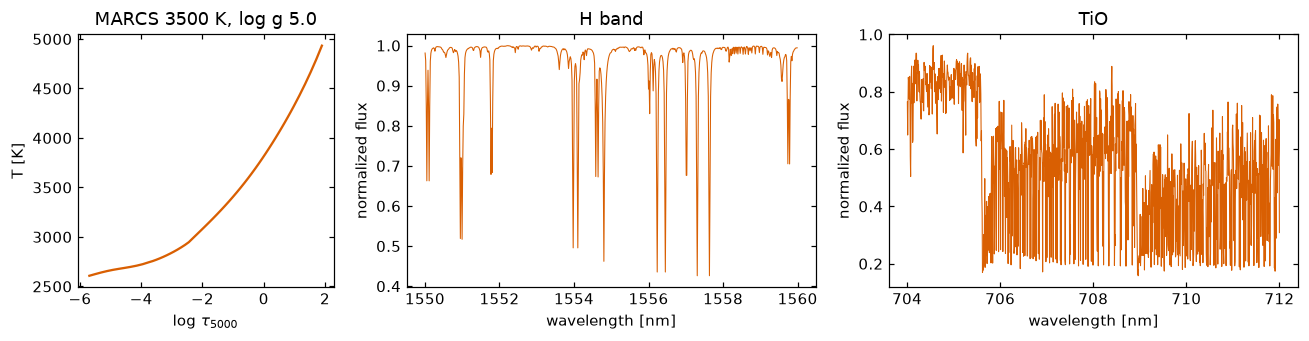

In [6]:
atmosphere_3500, columns_3500 = marcs_atmosphere(3500, 5.0, 0.0)
spectra_3500 = spectra(atmosphere_3500)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw={"width_ratios": [1, 1.6, 1.6]})
axes[0].plot(np.log10(columns_3500["tau_5000"]), columns_3500["temperature"], color=ORANGE)
axes[0].set(xlabel=r"$\log\,\tau_{5000}$", ylabel="T [K]", title="MARCS 3500 K, log g 5.0")
for ax, (name, spectrum) in zip(axes[1:], spectra_3500.items()):
    ax.plot(spectrum.wavelength_nm, spectrum.normalized_flux, color=ORANGE, lw=0.7)
    ax.set(xlabel="wavelength [nm]", ylabel="normalized flux", title=name)
fig.tight_layout()

## 4. MARCS and the initializer at 4000 K

At 4000 K both structures exist: the MARCS node and the Payne Zero initializer prediction. Synthesizing both with the same code isolates the effect of where the structure comes from.

log m range: MARCS -1.73 .. 1.49, initializer -3.17 .. 1.71
H band: RMS difference 0.0049, max 0.0191
TiO: RMS difference 0.0041, max 0.0182


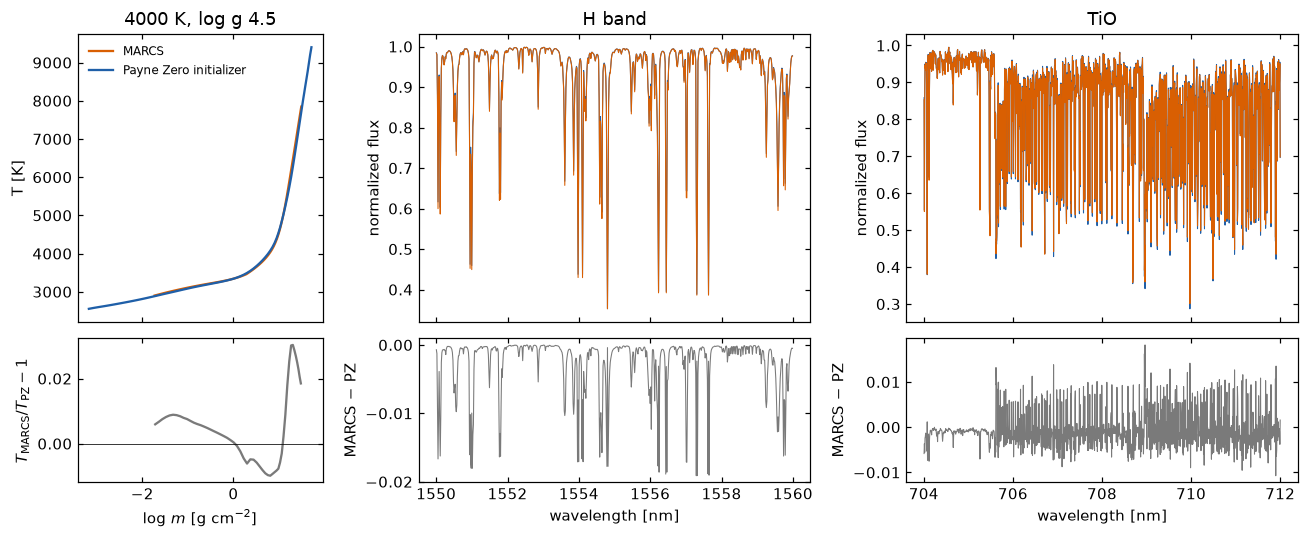

In [7]:
atmosphere_marcs, columns_marcs = marcs_atmosphere(4000, 4.5, 0.0)
initialized = initialize_atmosphere_from_labels(
    effective_temperature=4000,
    log_surface_gravity=4.5,
    metallicity=0.0,
    alpha_enhancement=0.0,
    microturbulence_km_s=MICROTURBULENCE_KM_S,
    device=DEVICE,
)
atmosphere_payne = initialized.structured_atmosphere
spectra_marcs = spectra(atmosphere_marcs)
spectra_payne = spectra(atmosphere_payne)

fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharex="col",
                         gridspec_kw={"width_ratios": [1, 1.6, 1.6], "height_ratios": [2, 1]})
for atmosphere, color, label in ((atmosphere_marcs, ORANGE, "MARCS"), (atmosphere_payne, BLUE, "Payne Zero initializer")):
    axes[0, 0].plot(np.log10(atmosphere["column_mass"]), atmosphere["temperature"], color=color, label=label)
axes[0, 0].set(ylabel="T [K]", title="4000 K, log g 4.5")
axes[0, 0].legend(frameon=False, fontsize=8)
log_m_payne = np.log10(atmosphere_payne["column_mass"])
log_m_marcs = np.log10(atmosphere_marcs["column_mass"])
overlap = (log_m_payne >= log_m_marcs[0]) & (log_m_payne <= log_m_marcs[-1])
marcs_on_payne = np.interp(log_m_payne[overlap], log_m_marcs, atmosphere_marcs["temperature"])
axes[1, 0].plot(log_m_payne[overlap], marcs_on_payne / atmosphere_payne["temperature"][overlap] - 1.0, color=MUTED)
print(f"log m range: MARCS {log_m_marcs[0]:.2f} .. {log_m_marcs[-1]:.2f}, initializer {log_m_payne[0]:.2f} .. {log_m_payne[-1]:.2f}")
axes[1, 0].axhline(0.0, color="k", lw=0.5)
axes[1, 0].set(xlabel=r"$\log\,m$ [g cm$^{-2}$]", ylabel=r"$T_{\rm MARCS}/T_{\rm PZ}-1$")

for column, name in enumerate(WINDOWS, start=1):
    marcs, payne = spectra_marcs[name], spectra_payne[name]
    axes[0, column].plot(payne.wavelength_nm, payne.normalized_flux, color=BLUE, lw=0.7)
    axes[0, column].plot(marcs.wavelength_nm, marcs.normalized_flux, color=ORANGE, lw=0.7)
    axes[0, column].set(title=name, ylabel="normalized flux")
    difference = marcs.normalized_flux - payne.normalized_flux
    axes[1, column].plot(marcs.wavelength_nm, difference, color=MUTED, lw=0.7)
    axes[1, column].set(xlabel="wavelength [nm]", ylabel="MARCS − PZ")
    print(f"{name}: RMS difference {np.sqrt(np.mean(difference**2)):.4f}, max {np.max(np.abs(difference)):.4f}")
fig.tight_layout()

Where the two depth grids overlap, the MARCS temperatures lie within about −1% to +3% of the initializer's. The MARCS model starts deeper, at log *m* ≈ −1.7, while the initializer reaches log *m* ≈ −3.2. The spectra differ by about 0.005 RMS in both windows, with single-pixel differences up to about 0.02; in the H band the MARCS lines are systematically deeper. This is the size of the structure-source effect at the edge of the initializer support. Below 4000 K there is no Payne Zero structure to compare against.

## 5. A temperature sequence

The same route runs continuously across the 4000 K limit. Each spectrum below uses a MARCS node at `logg` 5.0 and solar metallicity.

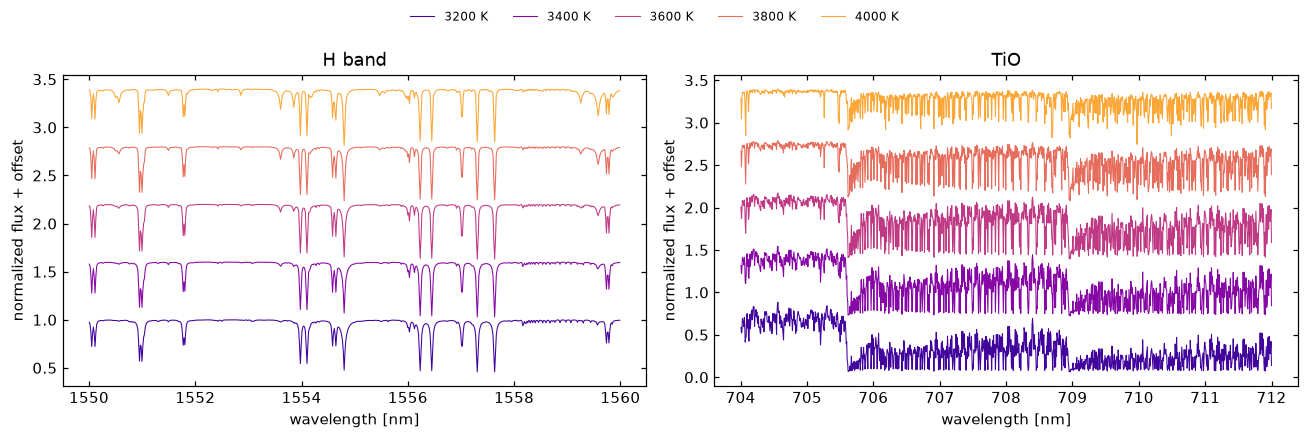

In [8]:
sequence = (3200, 3400, 3600, 3800, 4000)
sequence_spectra = {teff: spectra(marcs_atmosphere(teff, 5.0, 0.0)[0]) for teff in sequence}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = plt.cm.plasma(np.linspace(0.1, 0.8, len(sequence)))
for ax, name in zip(axes, WINDOWS):
    for offset, (teff, color) in enumerate(zip(sequence, colors)):
        spectrum = sequence_spectra[teff][name]
        ax.plot(spectrum.wavelength_nm, spectrum.normalized_flux + 0.6 * offset, color=color, lw=0.7, label=f"{teff} K")
    ax.set(xlabel="wavelength [nm]", ylabel="normalized flux + offset", title=name)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=8, ncol=len(sequence), loc="upper center")
fig.tight_layout(rect=(0, 0, 1, 0.93))

## 6. Abundances at a fixed structure

On this route, abundances enter through the vector handed to `build_structured_atmosphere`. Any element can be changed on its own, which is the element-by-element parameterization at the level of line formation. Carbon and oxygen matter most in M dwarfs because they set the molecular equilibrium: carbon locks oxygen into CO, leaving less for TiO, OH, and H₂O. The temperature structure is held fixed here, so these are line-formation responses, not self-consistent atmospheres.

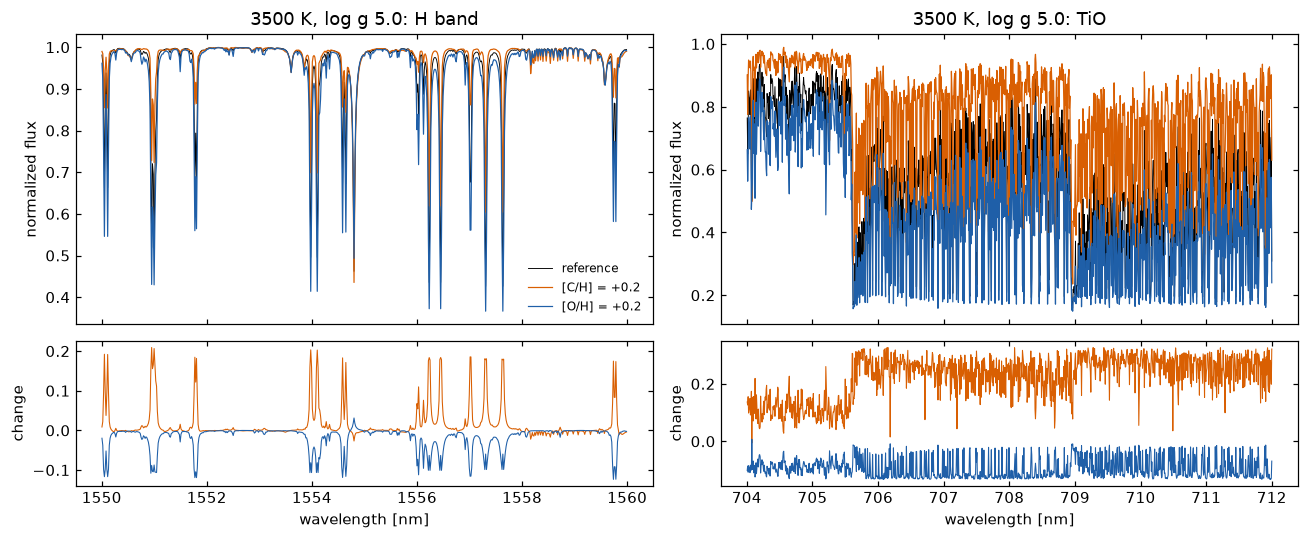

In [9]:
CARBON, OXYGEN = 6, 8
changes = {
    "reference": None,
    "[C/H] = +0.2": {CARBON: 0.2},
    "[O/H] = +0.2": {OXYGEN: 0.2},
}
abundance_spectra = {
    label: spectra(marcs_atmosphere(3500, 5.0, 0.0, offsets=offsets)[0])
    for label, offsets in changes.items()
}

fig, axes = plt.subplots(2, 2, figsize=(12, 5), sharex="col", gridspec_kw={"height_ratios": [2, 1]})
styles = {"reference": ("k", 0.6), "[C/H] = +0.2": (ORANGE, 0.8), "[O/H] = +0.2": (BLUE, 0.8)}
for column, name in enumerate(WINDOWS):
    reference = abundance_spectra["reference"][name]
    for label, by_window in abundance_spectra.items():
        color, width = styles[label]
        spectrum = by_window[name]
        axes[0, column].plot(spectrum.wavelength_nm, spectrum.normalized_flux, color=color, lw=width, label=label)
        if label != "reference":
            axes[1, column].plot(spectrum.wavelength_nm, spectrum.normalized_flux - reference.normalized_flux, color=color, lw=0.7)
    axes[0, column].set(title=f"3500 K, log g 5.0: {name}", ylabel="normalized flux")
    axes[1, column].set(xlabel="wavelength [nm]", ylabel="change")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()

Raising carbon by 0.2 dex weakens most of the strong H-band lines and lifts the whole TiO band, because more oxygen is bound in CO. Raising oxygen does the opposite. The weak features beyond 1558 nm, near the CO (3–0) band head, deepen with carbon. At 3500 K a 0.2 dex change in either element moves the TiO band by 0.1–0.3 in normalized flux, so C and O need to be free parameters in any M-dwarf fit.

## 7. Limitations

- The MARCS structure was computed with MARCS opacities, equation of state, and solar mixture. Payne Zero evaluates populations and the spectrum on that structure, using the MARCS electron density as given, so the result is a hybrid: the structure is not in radiative equilibrium under Payne Zero's own physics.
- The MARCS depth grid starts deeper than Payne Zero's, so the cores of the strongest lines see a different upper atmosphere.
- Section 6 changes abundances without recomputing the structure. For large changes in C/O this omits the structural response.
- Models are read node by node without interpolation. Fitting continuous labels needs interpolation in the MARCS grid or a structure emulator trained on it.
- Column mass is *P*_gas / *g*; radiation and turbulent pressure are omitted.
- The Payne Zero atmosphere solver is not used. Below 4000 K it starts from the nearest supported initializer and usually fails its convergence test for M dwarfs.